# Loading a new dataset: `artificial_defect_cAFM`

A new sample dataset, `artificial_defect_cAFM.npz`, was dropped into
`mexpsimu/data/` alongside the three BEPS presets from the quickstart
notebook. It needs **no code changes** to use -- `mexpsimu` discovers any
`.npz` file in the data directory automatically, as long as it uses the
same `image(s)` / `spectra` / `vstep` layout.

This dataset is different from the BEPS ones in a few ways worth calling
out as we go:

- it's **conductive AFM (cAFM)** data -- a current map plus local
  current-voltage (I-V) sweeps, not piezoresponse
- it has a **single image channel** instead of two
- its filename doesn't encode a physical scan size, so `scan_size_um` is
  unknown unless you supply it yourself
- its recorded voltage is a **unipolar ramp** (0 -> +1.25 V), not the
  bipolar triangle used for BEPS switching spectroscopy
- as the name suggests, it has a **localized defect** -- a small region of
  anomalously high current -- that we'll locate and inspect

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import mexpsimu

mexpsimu.list_presets()

['PTO_BEPS_1d3um', 'PTO_BEPS_1d7um', 'PTO_BEPS_3um', 'artificial_defect_cAFM']

The new preset shows up automatically. Let's load it and see what we
get.

In [2]:
scope = mexpsimu.Microscope("artificial_defect_cAFM")
scope

Microscope(dataset='artificial_defect_cAFM', image_shape=(50, 50), measurement_shape=(50, 50), position=TipPosition(row=25, col=25, x_um=None, y_um=None))

In [3]:
ds = scope.dataset
print("channels:       ", scope.list_channels())
print("image_shape:    ", ds.image_shape)
print("spectra_shape:  ", ds.spectra_shape)
print("scan_size_um:   ", ds.scan_size_um)
print("n_steps:        ", ds.spectra.shape[-1])
print("voltage_source: ", scope.voltage_source)

channels:        ['image']
image_shape:     (50, 50)
spectra_shape:   (50, 50)
scan_size_um:    None
n_steps:         128
voltage_source:  recorded


## Image scan

Only one channel this time, `image` -- here it's the recorded current map
rather than topography.

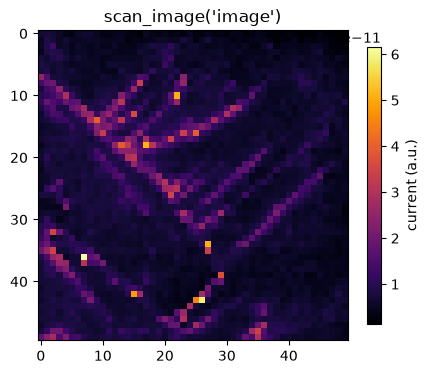

In [4]:
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(scope.scan_image("image"), cmap="inferno")
ax.set_title("scan_image('image')")
fig.colorbar(im, ax=ax, shrink=0.8, label="current (a.u.)")
plt.show()

## No physical scan size -- move the tip in pixel units

`scan_size_um` is `None` because this filename doesn't encode a size the
way `PTO_BEPS_1d3um.npz` etc. do. Asking to move in microns fails with a
clear error; pixel units always work regardless.

If you *do* know the real scan size, set it before constructing the
`Microscope` and micron-based moves work exactly as with the BEPS
datasets: `ds = mexpsimu.dataset.ScanDataset.load(path); ds.scan_size_um = 2.0`.

In [5]:
try:
    scope.move_tip(0.5, 0.5, units="um")
except ValueError as exc:
    print("ValueError:", exc)

# pixel units always work
scope.move_tip_pixel(col=25, row=25)

ValueError: dataset 'artificial_defect_cAFM' has no known physical scan size; use units='px' or set scan_size_um explicitly


TipPosition(row=25, col=25, x_um=None, y_um=None)

## Spectroscopy: a unipolar I-V ramp

Unlike the BEPS datasets' bipolar switching-spectroscopy loop, this
dataset's `vstep` is a one-way ramp from 0 to +1.25 V -- typical of a
conductive-AFM I-V sweep.

voltage_source: recorded
voltage range: [0.000, 1.250] V, monotonic: True


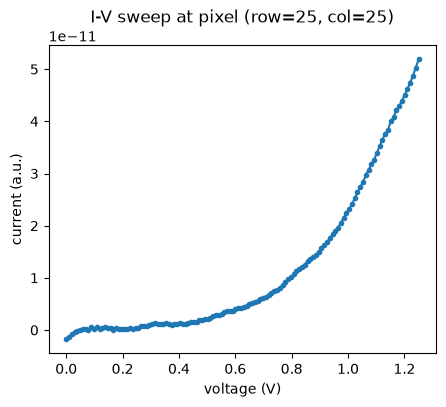

In [6]:
voltage, response = scope.spectroscopy()
print("voltage_source:", scope.voltage_source)
print(f"voltage range: [{voltage.min():.3f}, {voltage.max():.3f}] V, monotonic: {np.all(np.diff(voltage) >= 0)}")

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(voltage, response, marker=".")
ax.set_xlabel("voltage (V)")
ax.set_ylabel("current (a.u.)")
ax.set_title(f"I-V sweep at pixel (row={scope.position.row}, col={scope.position.col})")
plt.show()

## Finding the defect

The dataset name promises a defect. `spectroscopy()` only measures one
pixel at a time, but nothing stops us from reducing the *whole* recorded
`spectra` cube directly (it's just a numpy array on `scope.dataset.spectra`)
to build a per-pixel peak-current map and locate the outlier.

defect pixel:     (row=20, col=35), peak current=1.39e-09
background pixel: (row=5, col=5), peak current=2.18e-11
median peak current: 3.2e-11


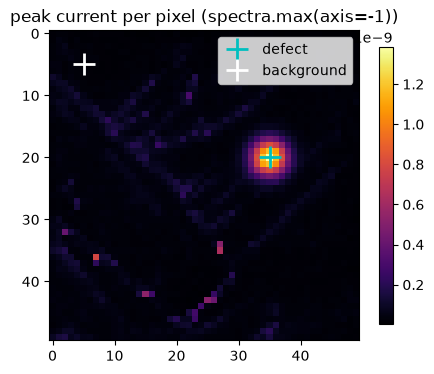

In [7]:
peak_current = scope.dataset.spectra.max(axis=-1)
defect_row, defect_col = np.unravel_index(np.argmax(peak_current), peak_current.shape)
background_row, background_col = 5, 5  # an arbitrary pixel away from the defect

print(f"defect pixel:     (row={defect_row}, col={defect_col}), peak current={peak_current[defect_row, defect_col]:.3g}")
print(f"background pixel: (row={background_row}, col={background_col}), peak current={peak_current[background_row, background_col]:.3g}")
print(f"median peak current: {np.median(peak_current):.3g}")

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(peak_current, cmap="inferno")
ax.plot(defect_col, defect_row, "c+", markersize=16, markeredgewidth=2, label="defect")
ax.plot(background_col, background_row, "w+", markersize=16, markeredgewidth=2, label="background")
ax.legend(loc="upper right")
ax.set_title("peak current per pixel (spectra.max(axis=-1))")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Now move the tip to each pixel with `move_tip_pixel` and compare their
I-V curves directly through the normal `spectroscopy()` API.

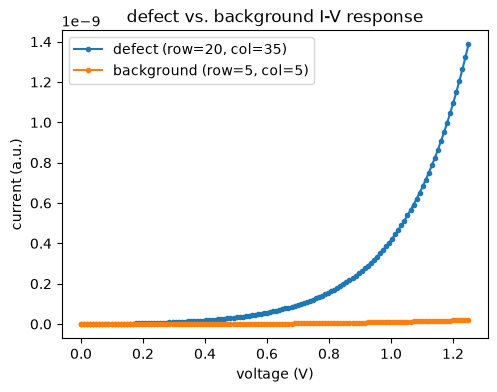

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for label, (row, col) in [("defect", (defect_row, defect_col)), ("background", (background_row, background_col))]:
    scope.move_tip_pixel(col=col, row=row)
    voltage, response = scope.spectroscopy()
    ax.plot(voltage, response, marker=".", label=f"{label} (row={row}, col={col})")
ax.set_xlabel("voltage (V)")
ax.set_ylabel("current (a.u.)")
ax.legend()
ax.set_title("defect vs. background I-V response")
plt.show()

## Recap

Adding `artificial_defect_cAFM.npz` to `mexpsimu/data/` was enough to make
it available as `mexpsimu.Microscope("artificial_defect_cAFM")` -- no
package changes needed, because it follows the same `image`/`spectra`/
`vstep` `.npz` layout as the bundled BEPS datasets. The main differences to
remember when working with a new dataset like this:

- check `dataset.scan_size_um` -- if it's `None`, use pixel units (or set
  it yourself) instead of microns
- check `scope.list_channels()` -- there may be only one image channel
- check `scope.voltage_source` and look at the `vstep` shape -- the
  excitation waveform isn't necessarily a bipolar BEPS loop
- the raw `scope.dataset.spectra` array is always available for whole-scan
  analysis (like the peak-current map above) that goes beyond the
  single-pixel `spectroscopy()` call

See `notebooks/quickstart.ipynb` for the full API tour on the original BEPS
datasets, and `README.md` for the package reference.